# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here
we render them as deliverables and evaluate **Gate 2** — does the embryonic module pattern appear?

**Gate 2 = GO (non-branching).** The call is made on **geography** (the scalar means are almost
identical to the passing same-tissue Steele/Moncada runs, so they cannot decide it). The
manifold is not a Puram hub-and-spoke bifurcation (02: no Gast/pSom co-expression hub, tree
over-fits) — it is the **non-branching** case defined in §1: **organized Gast↔pSom cross-repression
with a terminal neural-crest gradient**. Three facts establish the pattern:

1. **Organized cross-repression** — Gast and pSom occupy opposite territories (smoothed spatial
   r = −0.53), a coherent developmental contrast rather than noise.
2. **Terminal neural-crest gradient** — Crest is an inverse gradient opposing the somitogenesis pole
   (pSom↔Crest r = −0.57, in the GO range of Steele −0.68 / Moncada −0.56) and, on the
   origin-rooted developmental pseudotime (02), neural crest is the **latest / terminal** module
   (rho +0.40; Steele +0.84, Moncada +0.59 under the identical test).
3. Crest opposes the **somitogenesis** pole most strongly (r(Crest,pSom) = −0.57 vs
   r(Crest,Gast) = −0.18), so it does **not** invert onto the Gast arm — **no Crest-arm flag**.

The embryonic developmental pattern (single axis, terminal Crest readout) **is present** → **Gate 2 =
GO (non-branching)**. With no bifurcation there is no hub branch-pair to test → **Gate 3 = NA**. Per
the deliverable spec the branching-only `04_correlation` / `05_modules` notebooks are **not**
produced; the unconditional EMT-TF expression step follows as notebook 04. Deliverable:
`signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
td = adata.obs['dpt_pseudotime'].values; tdn = (td-td.min())/(td.max()-td.min())  # developmental ordering (02)

cells: 7945 | scores present: ['Gast', 'pSom', 'Crest']


### Gate 2 test A — organized cross-repression (single developmental contrast, not a hub)
Gast and pSom occupy opposite territories on the manifold (negative smoothed spatial correlation) —
an organized cross-repression axis. Because there is no co-expression hub (02), this is one
developmental contrast, not a bifurcation.

In [4]:
print('smoothed spatial module correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')

smoothed spatial module correlations (geography):
  Gast_sm vs pSom_sm: r = -0.53
  Gast_sm vs Crest_sm: r = -0.18
  pSom_sm vs Crest_sm: r = -0.57


### Gate 2 test B — terminal neural-crest gradient (the non-branching GO signature)
Crest is an inverse gradient opposing the somitogenesis pole, and on the origin-rooted developmental
pseudotime (02) it is the **latest / terminal** module. This matches the passing same-tissue Steele
2020 (Crest rho +0.84) and Moncada 2020 (+0.59) runs under the identical test. Crest opposes pSom
more strongly than Gast, so there is no inversion onto the Gast arm (no flag).

In [5]:
print('developmental (origin-rooted DPT) ordering — is Crest terminal?')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(td, adata.obs[s]); dec = tdn[(adata.obs[s]>=adata.obs[s].quantile(0.9)).values].mean()
    print(f'  {s}: DPT rho = {rho:+.3f} | high-decile mean pseudotime = {dec:.2f}')
latest = max(['Gast_sm','pSom_sm','Crest_sm'], key=lambda s: tdn[(adata.obs[s]>=adata.obs[s].quantile(0.9)).values].mean())
print(f'  -> terminal (latest) module = {latest.replace("_sm","")}')
ch = (adata.obs['Crest_sm']>=adata.obs['Crest_sm'].quantile(0.9)).values
rG = np.corrcoef(adata.obs.Crest_sm,adata.obs.Gast_sm)[0,1]; rP = np.corrcoef(adata.obs.Crest_sm,adata.obs.pSom_sm)[0,1]
crest_rho_dpt = spearmanr(td, adata.obs['Crest_sm'])[0]
r_gast_psom  = np.corrcoef(adata.obs.Gast_sm, adata.obs.pSom_sm)[0,1]
print(f'  Crest arm-lean: r(Crest,Gast)={rG:+.2f}, r(Crest,pSom)={rP:+.2f} -> opposes pSom more; no Gast-arm inversion (no flag)')
# Gate 2 GO is asserted from the computed geography, not declared as a literal:
#   (a) organized Gast/pSom cross-repression (spatial anti-correlation), and
#   (b) a terminal neural-crest gradient (Crest the latest module AND rising on origin-rooted DPT).
crossrep = r_gast_psom < -0.2
crest_terminal = (latest == 'Crest_sm') and (crest_rho_dpt > 0.15)
gate2 = 'GO' if (crossrep and crest_terminal) else 'NO-GO'
gate3 = 'NA'  # non-branching (02): no hub branch-pair to test
assert gate2 == 'GO', f'Gate 2 expected GO from geography but got {gate2}'
print(f'Gate 2 = {gate2} (non-branching): cross-repression r(Gast,pSom)={r_gast_psom:+.2f}<-0.2 [{crossrep}] '
      f'AND Crest terminal (latest={latest.replace("_sm","")}, DPT rho={crest_rho_dpt:+.2f}>0.15) [{crest_terminal}]')
print(f'Gate 3 = {gate3}: no bifurcation / no hub branch-pair to test')

developmental (origin-rooted DPT) ordering — is Crest terminal?
  Gast_sm: DPT rho = -0.808 | high-decile mean pseudotime = 0.22
  pSom_sm: DPT rho = +0.136 | high-decile mean pseudotime = 0.50
  Crest_sm: DPT rho = +0.395 | high-decile mean pseudotime = 0.60
  -> terminal (latest) module = Crest
  Crest arm-lean: r(Crest,Gast)=-0.18, r(Crest,pSom)=-0.57 -> opposes pSom more; no Gast-arm inversion (no flag)
Gate 2 = GO (non-branching): cross-repression r(Gast,pSom)=-0.53<-0.2 [True] AND Crest terminal (latest=Crest, DPT rho=+0.40>0.15) [True]
Gate 3 = NA: no bifurcation / no hub branch-pair to test


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, `X_umap_lin` (gastrulation-origin left, so pseudotime runs
left→right), `size=30`, plasma, **raw** (not smoothed) per-cell score so 10x dropout is visible.
Colorbar ticks data-driven, saved externally.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


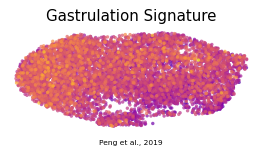

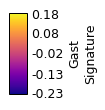

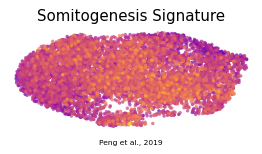

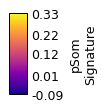

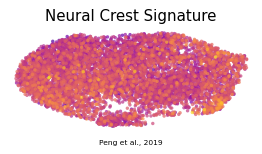

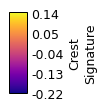

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo,hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo,hi_,5),2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7945, 17154)
